## Problem 4 

a) a0: 0.19634954084936207 vs pi/16 = 0.19634954084936207
a) max |an - hand|: 4.770180959535779e-16
a) max |bn - hand|: 5.189127122787185e-16
b) a0: 0.39269908169872414 vs pi/8 = 0.39269908169872414
b) max |an - hand|: 8.901135671040259e-16


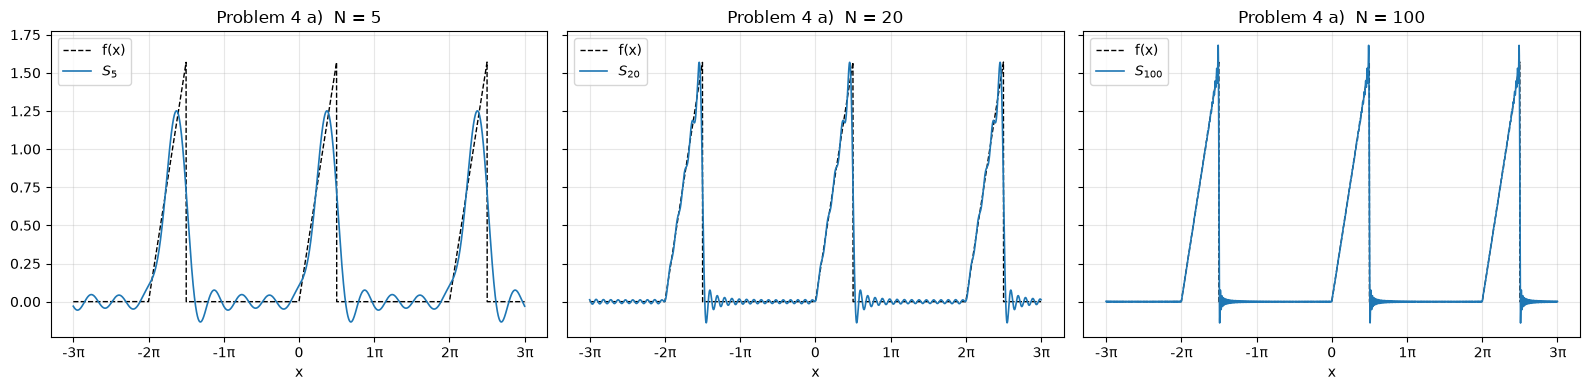

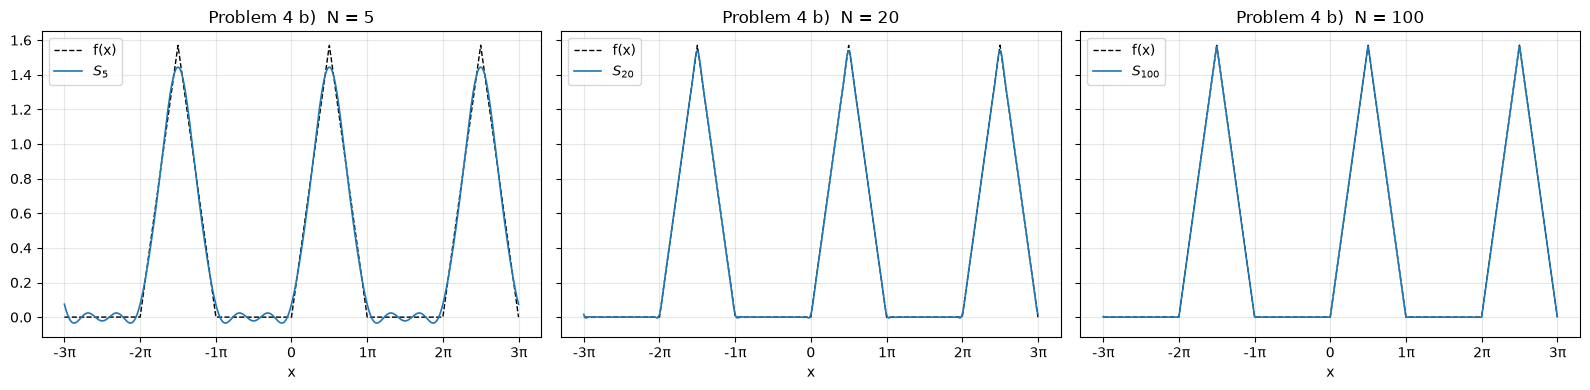

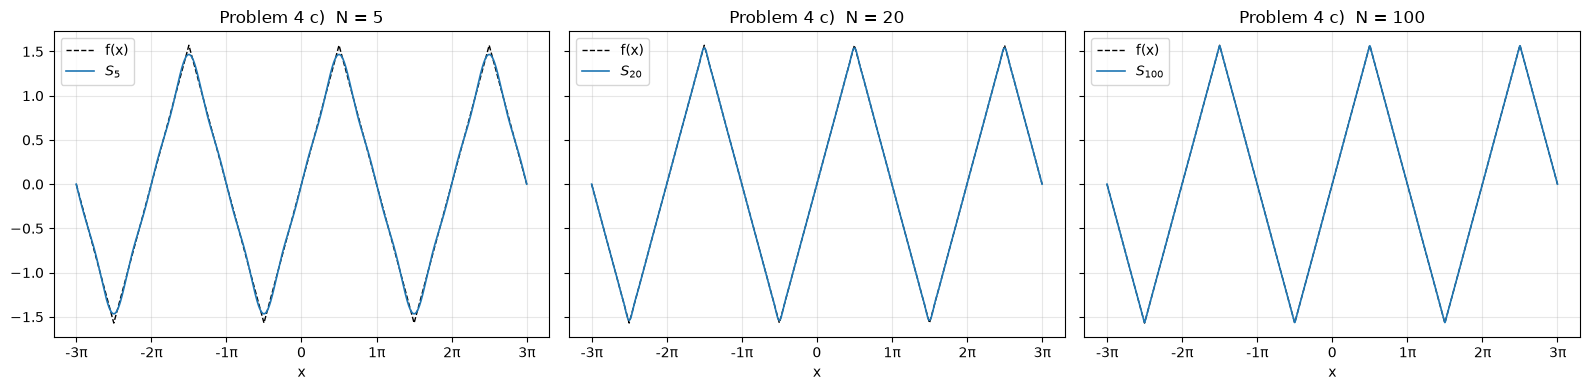

In [1]:
# %% Setup
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

pi = np.pi

# %% Functions on [-pi, pi]
def f_a(x):
    return np.where((x >= 0) & (x <= pi/2), x, 0.0)

def f_b(x):
    return np.where((x > 0) & (x < pi/2), x,
           np.where(x > pi/2, pi - x, 0.0))

def f_c(x):
    return np.where(x < -pi/2, -pi - x,
           np.where(x < pi/2, x, pi - x))

# breakpoints 
problems = {
    "a)": (f_a, [0, pi/2]),
    "b)": (f_b, [0, pi/2]),
    "c)": (f_c, [-pi/2, pi/2]),
}

def periodic(f):
    """2pi-periodic continuation of f, defined on [-pi, pi]."""
    return lambda x: f((np.asarray(x) + pi) % (2*pi) - pi)

# fourier coefficients (numerical integration)
def coeffs(f, pts, N):
    g = lambda x: float(f(np.array(x)))
    a0 = quad(g, -pi, pi, points=pts, limit=200)[0] / (2*pi)
    an = np.array([quad(lambda x: g(x)*np.cos(n*x), -pi, pi, points=pts, limit=200)[0]/pi
                   for n in range(1, N+1)])
    bn = np.array([quad(lambda x: g(x)*np.sin(n*x), -pi, pi, points=pts, limit=200)[0]/pi
                   for n in range(1, N+1)])
    return a0, an, bn

# partial sum S_N 
def S(x, a0, an, bn, N):
    n = np.arange(1, N+1)[:, None]            # shape (N, 1)
    return a0 + (an[:N, None]*np.cos(n*x) + bn[:N, None]*np.sin(n*x)).sum(axis=0)

Nmax = 100
a0_a, an_a, bn_a = coeffs(f_a, [0, pi/2], Nmax)
n = np.arange(1, Nmax+1)
an_a_hand = np.sin(n*pi/2)/(2*n) + (np.cos(n*pi/2) - 1)/(pi*n**2)
bn_a_hand = np.sin(n*pi/2)/(pi*n**2) - np.cos(n*pi/2)/(2*n)
print("a) a0:", a0_a, "vs pi/16 =", pi/16)
print("a) max |an - hand|:", np.abs(an_a - an_a_hand).max())
print("a) max |bn - hand|:", np.abs(bn_a - bn_a_hand).max())

a0_b, an_b, bn_b = coeffs(f_b, [0, pi/2], Nmax)
an_b_hand = np.where(n % 4 == 2, -4/(pi*n**2), 0.0)
print("b) a0:", a0_b, "vs pi/8 =", pi/8)
print("b) max |an - hand|:", np.abs(an_b - an_b_hand).max())

# plot f and S_N for N = 5, 20, 100 over (-3pi, 3pi)
x = np.linspace(-3*pi, 3*pi, 6000)
Ns = [5, 20, 100]

for name, (f, pts) in problems.items():
    a0, an, bn = coeffs(f, pts, Nmax)
    fp = periodic(f)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, N in zip(axes, Ns):
        ax.plot(x, fp(x), "k--", lw=1, label="f(x)")
        ax.plot(x, S(x, a0, an, bn, N), lw=1.2, label=f"$S_{{{N}}}$")
        ax.set_title(f"Problem 4 {name}  N = {N}")
        ax.set_xlabel("x")
        ax.set_xticks(np.arange(-3, 4)*pi)
        ax.set_xticklabels([f"{k}π" if k else "0" for k in range(-3, 4)])
        ax.grid(alpha=0.3)
        ax.legend()
    fig.tight_layout()
    fig.savefig(f"problem4_{name[0]}.png", dpi=130)
plt.show()